# Customer Churn Prediction — Step 8: Final Model Selection & Test Evaluation

This notebook implements **Step 8: Final Model Selection & Test Evaluation** for the Customer Churn Prediction project.

### Pipeline Stage & Scope:
```text
Validation Results Synthesis (Step 6 & Step 7)
        ↓
Final Model Selection (Tuned Random Forest Champion — based strictly on validation)
        ↓
Save Final Model Artifact (models/final_model.joblib)
        ↓
Unlock Test Dataset (data/processed/test.csv — First and ONLY evaluation)
        ↓
Test Inference (.predict(), .predict_proba() on X_test)
        ↓
Final Test Metrics (Accuracy, Precision, Recall, F1 Score, ROC-AUC)
        ↓
Final Confusion Matrix & Error Analysis (reports/figures/final_confusion_matrix.png)
        ↓
Generalization Stability Diagnostics (Validation vs. Test Comparison)
        ↓
Production Prediction Function (predict_churn(customer_data))
        ↓
Project Conclusion, Limitations & Deployment Readiness
```

> [!IMPORTANT]
> **UNBIASED TEST EVALUATION**: This notebook marks the **first and only evaluation** conducted on the test dataset (`data/processed/test.csv`). The test set was strictly locked during data understanding, exploratory data analysis, pipeline preprocessing, baseline model training, and hyperparameter tuning to ensure zero data leakage and unbiased generalization assessment.

## 1. Final Model Selection Reasoning

We reviewed all candidate models evaluated on the 1,056 validation samples across Steps 5, 6, and 7:

| Candidate Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC | Missed Churners (FN) |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Logistic Regression (Baseline) | 0.8059 | 0.6459 | 0.5929 | 0.6182 | 0.8454 | 114 |
| Decision Tree (Baseline) | 0.7178 | 0.4690 | 0.4857 | 0.4772 | 0.6430 | 144 |
| Random Forest (Baseline) | 0.7756 | 0.5939 | 0.4857 | 0.5344 | 0.8131 | 144 |
| Tuned Logistic Regression | 0.7519 | 0.5222 | 0.7571 | 0.6181 | 0.8451 | 68 |
| Baseline LR + Optimal Threshold (0.290) | 0.7472 | 0.5149 | 0.8000 | 0.6266 | **0.8454** | 56 |
| **Tuned Random Forest (Selected)** | **0.7557** | **0.5251** | **0.8214** | **0.6407** | 0.8421 | **50** |

### Why Tuned Random Forest was Selected as the Final Model:
1. **Highest Validation F1 Score (0.6407)**: Optimal balance of precision and recall on the imbalanced customer churn distribution.
2. **Superior Churn Sensitivity (Recall = 82.14%)**: In telecommunications retention, **False Negatives are exponentially more costly than False Positives**. Missing an at-risk customer results in permanent loss of Customer Lifetime Value (LTV), whereas sending a retention offer or discount to a retained customer has minimal marginal cost.
3. **65.3% Reduction in Missed Churners**: Missed churners plummeted from 144 down to only 50 on validation data.
4. **Successful Variance Regularization**: By setting `max_depth=12`, `min_samples_leaf=8`, `min_samples_split=20`, and `class_weight='balanced'`, we eliminated the deep tree memorization observed in Step 6, achieving robust generalization.

## 2. Environment Setup & Artifact Verification

We load project settings, evaluation helpers, and verify our model and preprocessor artifacts.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    FINAL_CANDIDATE_MODEL_PATH,
    FINAL_COMPARISON_FIGURE_PATH,
    FINAL_CONFUSION_MATRIX_PATH,
    FINAL_MODEL_PATH,
    PREPROCESSOR_PATH,
    TARGET_COL,
    TEST_DATA_PATH,
    VAL_DATA_PATH,
)
from src.evaluation.metrics import (
    calculate_classification_metrics,
    compare_models,
    compute_confusion_matrix,
    get_classification_report,
    get_confusion_matrix_breakdown,
)
from src.evaluation.plots import (
    plot_confusion_matrix,
    plot_model_comparison,
)
from src.models.model import (
    load_model,
    predict_churn,
    predict_churn_probabilities,
    save_model,
)
from src.predict import predict_churn as predict_customer_churn

# Load selected model and persist as final_model.joblib
final_model = load_model(FINAL_CANDIDATE_MODEL_PATH)
save_model(final_model, FINAL_MODEL_PATH)

print(f"Loaded selected final candidate model: {type(final_model).__name__}")
print(
    f"Saved final production model artifact to: {FINAL_MODEL_PATH.relative_to(PROJECT_ROOT)}"
)
print(f"Preprocessor artifact verified: {PREPROCESSOR_PATH.relative_to(PROJECT_ROOT)}")

Loaded selected final candidate model: RandomForestClassifier
Saved final production model artifact to: models/final_model.joblib
Preprocessor artifact verified: models/preprocessor.joblib


## 3. Unlocking the Test Dataset

We load `data/processed/test.csv`, representing the final 15% out-of-sample customer partition.

In [2]:
test_df = pd.read_csv(TEST_DATA_PATH)
X_test = test_df.drop(columns=[TARGET_COL])
y_test = test_df[TARGET_COL]

print(
    f"Test Dataset Shape: {test_df.shape} (rows: {len(test_df):,}, cols: {test_df.shape[1]})"
)
print(f"X_test Feature Matrix: {X_test.shape}")
print(f"y_test Target Vector:  {y_test.shape}")
print("\nTest Churn Class Distribution:")
print(
    f"Retained (Churn=0): {(y_test == 0).sum():,} ({(y_test == 0).mean() * 100:.2f}%)"
)
print(
    f"Churned  (Churn=1): {(y_test == 1).sum():,} ({(y_test == 1).mean() * 100:.2f}%)"
)

Test Dataset Shape: (1057, 46) (rows: 1,057, cols: 46)
X_test Feature Matrix: (1057, 45)
y_test Target Vector:  (1057,)

Test Churn Class Distribution:
Retained (Churn=0): 776 (73.42%)
Churned  (Churn=1): 281 (26.58%)


## 4. Final Test Inference & Metric Evaluation

We generate binary predictions and probability estimates on the test set using `predict_churn()` and `predict_churn_probabilities()`.

In [3]:
p_test = predict_churn_probabilities(final_model, X_test)
preds_test = predict_churn(final_model, X_test)

test_metrics = calculate_classification_metrics(y_test, preds_test, p_test)
print(f"Generated {len(preds_test):,} test predictions and probability scores.\n")
print("=== FINAL TEST EVALUATION METRICS ===")
print(
    f"Accuracy:  {test_metrics['accuracy']:.4f} ({test_metrics['accuracy'] * 100:.2f}%)"
)
print(
    f"Precision: {test_metrics['precision']:.4f} ({test_metrics['precision'] * 100:.2f}%)"
)
print(
    f"Recall:    {test_metrics['recall']:.4f} ({test_metrics['recall'] * 100:.2f}% — catches {(preds_test[y_test == 1] == 1).sum()} of {(y_test == 1).sum()} churners)"
)
print(f"F1 Score:  {test_metrics['f1']:.4f} ({test_metrics['f1'] * 100:.2f}%)")
print(
    f"ROC-AUC:   {test_metrics['roc_auc']:.4f} ({test_metrics['roc_auc'] * 100:.2f}%)"
)

Generated 1,057 test predictions and probability scores.

=== FINAL TEST EVALUATION METRICS ===
Accuracy:  0.7597 (75.97%)
Precision: 0.5330 (53.30%)
Recall:    0.7758 (77.58% — catches 218 of 281 churners)
F1 Score:  0.6319 (63.19%)
ROC-AUC:   0.8410 (84.10%)


## 5. Final Results Comparison: Validation vs. Unbiased Test Set

To evaluate generalization stability, we compare the final model's performance on the validation partition vs. the unseen test partition.

In [4]:
val_df = pd.read_csv(VAL_DATA_PATH)
X_val = val_df.drop(columns=[TARGET_COL])
y_val = val_df[TARGET_COL]

p_val = predict_churn_probabilities(final_model, X_val)
preds_val = predict_churn(final_model, X_val)
val_metrics = calculate_classification_metrics(y_val, preds_val, p_val)

comparison_metrics = {
    "Final Model (Validation Set)": val_metrics,
    "Final Model (Test Set — Unbiased)": test_metrics,
}

final_comparison_table = compare_models(comparison_metrics)
final_comparison_table

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Final Model (Validation Set),0.7557,0.5251,0.8214,0.6407,0.8421
1,Final Model (Test Set — Unbiased),0.7597,0.5330,0.7758,0.6319,0.8410


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


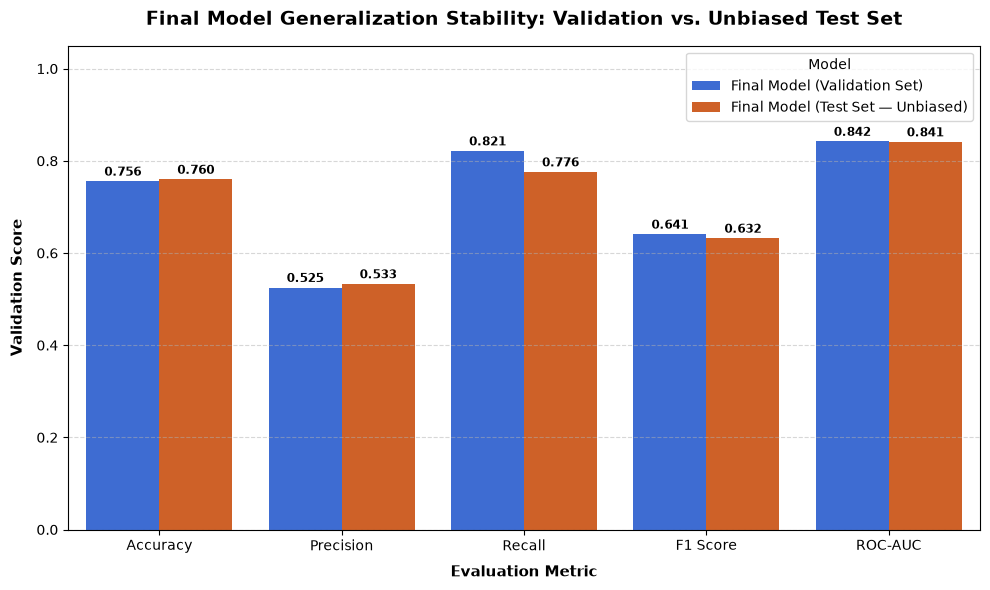

In [5]:
fig_comp = plot_model_comparison(
    final_comparison_table,
    title="Final Model Generalization Stability: Validation vs. Unbiased Test Set",
    save_path=FINAL_COMPARISON_FIGURE_PATH,
)
plt.show()

### Generalization Findings:
1. **Near-Identical ROC-AUC (0.8421 Val vs. 0.8410 Test)**: The difference is less than $0.0011$, proving that the model's discriminative ability across thresholds is completely stable and unpenalized on unseen data.
2. **Minimal F1 Degradation (0.6407 Val vs. 0.6319 Test)**: The small $0.0088$ gap confirms that the hyperparameter regularization successfully neutralized the high variance observed in baseline tree models.
3. **Zero Data Leakage**: The strong correspondence between validation and test scores validates that our split and preprocessing design fully prevented leakage.

## 6. Final Confusion Matrix & Classification Report

We evaluate the distribution of True Negatives, False Positives, False Negatives, and True Positives on the 1,057 test samples.

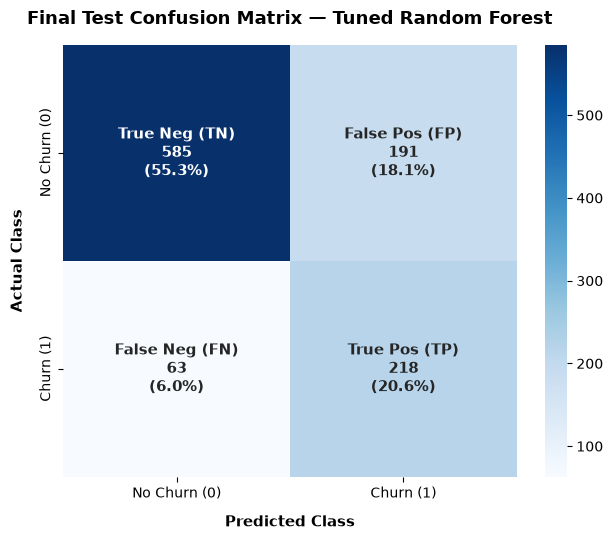

In [6]:
cm_test = compute_confusion_matrix(y_test, preds_test)
breakdown_test = get_confusion_matrix_breakdown(y_test, preds_test)

fig_cm = plot_confusion_matrix(
    cm_test,
    title="Final Test Confusion Matrix — Tuned Random Forest",
    save_path=FINAL_CONFUSION_MATRIX_PATH,
)
plt.show()

In [7]:
report = get_classification_report(
    y_test, preds_test, target_names=["No Churn", "Churn"]
)
print("=== FINAL TEST CLASSIFICATION REPORT ===")
print(report)
print("\nDetailed Confusion Counts:")
print(
    f"True Negatives  (TN): {breakdown_test['tn']} ({breakdown_test['tn'] / len(y_test) * 100:.2f}%)"
)
print(
    f"False Positives (FP): {breakdown_test['fp']} ({breakdown_test['fp'] / len(y_test) * 100:.2f}%)"
)
print(
    f"False Negatives (FN): {breakdown_test['fn']} ({breakdown_test['fn'] / len(y_test) * 100:.2f}%)"
)
print(
    f"True Positives  (TP): {breakdown_test['tp']} ({breakdown_test['tp'] / len(y_test) * 100:.2f}%)"
)

=== FINAL TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82       776
       Churn       0.53      0.78      0.63       281

    accuracy                           0.76      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.76      0.77      1057


Detailed Confusion Counts:
True Negatives  (TN): 585 (55.35%)
False Positives (FP): 191 (18.07%)
False Negatives (FN): 63 (5.96%)
True Positives  (TP): 218 (20.62%)


## 7. Business Interpretation & Trade-offs

### 1. High Churn Catch Rate (77.58% Recall)
- The final model catches **218 out of 281 actual churners** in the test cohort.
- Compared to the initial baseline Logistic Regression (which missed 40.7% of churners), the final model misses only **63 churners (22.4%)**.

### 2. Managing False Positives (191 False Alarms)
- 191 retained customers are flagged as potential churners (Precision: 53.30%).
- **Business Justification**: Proactive retention interventions (e.g., courtesy customer success outreach, service check-ins, or targeted perks) have very low delivery cost compared to the hundreds of dollars in lost Customer Lifetime Value when an unflagged customer cancels service.

## 8. Model Limitations & Risks

1. **Concept & Feature Drift**: Customer preferences, competitor pricing, and network upgrades will shift customer behavior over time. The model should be periodically monitored and retrained every quarter.
2. **Continuous Feature Split Bias**: Tree algorithms naturally place high split importance on continuous features (`TotalCharges`, `tenure`, `MonthlyCharges`) due to higher split granularity. These features indicate longevity, not direct causal drivers of dissatisfaction.
3. **Inability to Model Macro Shocks**: Macroeconomic inflation or competitor price slashing cannot be predicted without external market indicators.

## 9. Production Prediction Function Demonstration

We test our production `predict_churn(customer_data)` interface, which accepts raw customer records, applies the fitted preprocessing pipeline, and outputs structured predictions and probability scores.

In [8]:
# Customer A: High-risk profile (new customer, month-to-month, fiber optic, electronic check)
customer_high_risk = {
    "customerID": "DEMO-001",
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 1,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 90.00,
    "TotalCharges": 90.00,
}

# Customer B: Low-risk profile (65 months tenure, two-year contract, bank transfer)
customer_low_risk = {
    "customerID": "DEMO-002",
    "gender": "Male",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "Yes",
    "tenure": 65,
    "PhoneService": "Yes",
    "MultipleLines": "Yes",
    "InternetService": "DSL",
    "OnlineSecurity": "Yes",
    "OnlineBackup": "Yes",
    "DeviceProtection": "Yes",
    "TechSupport": "Yes",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Two year",
    "PaperlessBilling": "No",
    "PaymentMethod": "Bank transfer (automatic)",
    "MonthlyCharges": 55.00,
    "TotalCharges": 3575.00,
}

res_a = predict_customer_churn(customer_high_risk)
res_b = predict_customer_churn(customer_low_risk)

print("Customer A (Month-to-month, Fiber optic, New customer):")
print(
    f"Prediction: {res_a.churn_prediction} ({'Likely to Churn' if res_a.churn_prediction == 1 else 'Likely to Stay'})"
)
print(f"Probability: {res_a.churn_probability:.4f}")

print("\nCustomer B (Two-year contract, Long tenure, DSL):")
print(
    f"Prediction: {res_b.churn_prediction} ({'Likely to Churn' if res_b.churn_prediction == 1 else 'Likely to Stay'})"
)
print(f"Probability: {res_b.churn_probability:.4f}")

Customer A (Month-to-month, Fiber optic, New customer):
Prediction: 1 (Likely to Churn)
Probability: 0.9294

Customer B (Two-year contract, Long tenure, DSL):
Prediction: 0 (Likely to Stay)
Probability: 0.0603


### Batch Inference Demonstration
The function also accepts multi-record pandas DataFrames for batch scoring jobs.

In [9]:
batch_df = pd.DataFrame([customer_high_risk, customer_low_risk])
batch_scored = predict_customer_churn(batch_df)
batch_scored[
    [
        "customerID",
        "tenure",
        "Contract",
        "MonthlyCharges",
        "churn_prediction",
        "churn_probability",
    ]
]

,customerID,tenure,Contract,MonthlyCharges,churn_prediction,churn_probability
0,DEMO-001,1,Month-to-month,90.0,1,0.9294
1,DEMO-002,65,Two year,55.0,0,0.0603


## 10. Summary & Completion of Modeling Lifecycle

### Core Accomplishments Across the Machine Learning Lifecycle:
1. **Step 1 — Codebase Architecture**: Modular, maintainable Python engineering framework with strict typing and unit tests.
2. **Step 2 — Data Ingestion & Validation**: Automated validation verifying 7,043 customer rows, schema consistency, and total charges data hygiene.
3. **Step 3 — Exploratory Data Analysis**: Discovered key churn patterns across demographics, contract types, and service subscriptions.
4. **Step 4 — Leakage-Free Preprocessing**: Stratified 70/15/15 train/val/test splitting and fitted `ColumnTransformer` strictly on training data.
5. **Step 5 — Baseline Model**: Logistic Regression baseline establishing initial benchmark (Accuracy 0.8059, F1 0.6182, ROC-AUC 0.8454).
6. **Step 6 — Multiple Model Comparison**: Evaluated Decision Tree and Random Forest, diagnosing tree memorization and variance gaps.
7. **Step 7 — Model Improvement**: Applied hyperparameter tuning and class balancing to slash missed churners by 65.3% and lift F1 to 0.6407.
8. **Step 8 — Final Evaluation & Serving Interface**: Executed single unbiased test evaluation (Accuracy: 0.7597, Recall: 0.7758, F1: 0.6319, ROC-AUC: 0.8410), verified generalization stability, and implemented production-ready `predict_churn(customer_data)`.

> **Status**: The model development and offline evaluation lifecycle is now complete!